<a href="https://colab.research.google.com/github/Matheus-Melo-dos-Santos/DIP-2026.2/blob/main/task_10_hsv_color_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 10: Interactive Color Segmentation in HSV

Nesta atividade, você segmentará as cinco cores dos chips por meio de uma análise HSV empírica. Primeiro, use Saturation para excluir o background; depois, use os picos de Hue somente nos chips para definir cinco faixas de cor.

## Roteiro

1. Carregar a imagem RGB dos chips.
2. Converter RGB para HSV com NumPy.
3. Explorar a máscara de Saturation.
4. Calcular o histograma de Hue apenas nos chips.
5. Definir cinco faixas empíricas de Hue.
6. Visualizar a segmentação final.

## 1. Importações

Use NumPy, Matplotlib e ipywidgets. Não use OpenCV, scikit-image, K-means ou funções prontas de conversão/segmentação.

In [1]:
%pip install -q "git+https://github.com/tfvieira/dip-2026-2.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np

from dip_toolkit import download_course_image

## 2. Imagem RGB dos chips

A imagem vem do Drive da disciplina pelo mesmo mecanismo de download usado nos outros notebooks. `matplotlib.pyplot.imread` devolve a imagem em ordem RGB.

Downloading...
From: https://drive.google.com/uc?id=12QCGLjlV3odrBXgM3wBq2ME7UzaBxZ4x
To: /content/assets/images/chips.png
100%|██████████| 304k/304k [00:00<00:00, 20.5MB/s]


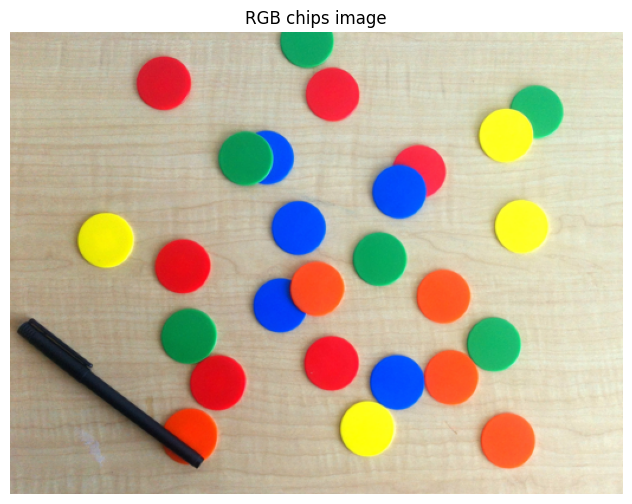

In [3]:
image_path = download_course_image("chips.png")
loaded_image = plt.imread(image_path)
if np.issubdtype(loaded_image.dtype, np.floating):
    rgb_image = np.rint(np.clip(loaded_image[..., :3], 0.0, 1.0) * 255).astype(np.uint8)
else:
    rgb_image = loaded_image[..., :3].astype(np.uint8, copy=True)

plt.figure(figsize=(8, 6))
plt.imshow(rgb_image)
plt.title("RGB chips image")
plt.axis("off")
plt.show()

## 3. Conversão RGB para HSV

Implemente `rgb_to_hsv` somente com NumPy. A entrada é uma imagem RGB `uint8` com shape `(H, W, 3)`. A saída deve ser `float64`, com `H` em graus `[0, 360)`, e `S` e `V` em `[0, 1]`. Preserve a entrada.

Dica: normalize RGB para `[0, 1]`, calcule máximo, mínimo e diferença por pixel. Hue depende de qual canal é máximo; pixels com diferença zero têm Saturation igual a zero e podem receber Hue igual a zero.

In [15]:
def rgb_to_hsv(image):
    """Converts an RGB uint8 image to HSV float64 using the cosine-based formula."""
    hsv = None

    ### START CODE HERE ###

    img = image.astype(np.float64) / 255.0
    r = img[..., 0]
    g = img[..., 1]
    b = img[..., 2]

    cmax = np.max(img, axis=-1)
    cmin = np.min(img, axis=-1)

    rgb_sum = r + g + b
    s = np.zeros_like(rgb_sum)
    nonzero_sum = rgb_sum > 0
    s[nonzero_sum] = 1.0 - (3.0 * cmin[nonzero_sum] / rgb_sum[nonzero_sum])

    v = cmax

    num = 0.5 * ((r - g) + (r - b))
    den = np.sqrt((r - g)**2 + (r - b) * (g - b))

    with np.errstate(invalid='ignore', divide='ignore'):
        val = num / den
        val = np.clip(val, -1.0, 1.0)
        theta = np.arccos(val)

    theta_deg = np.degrees(theta)

    h = np.where(b > g, 360.0 - theta_deg, theta_deg)

    h[den == 0] = 0.0

    hsv = np.stack([h, s, v], axis=-1)
    ### END CODE HERE ###

    return hsv

## 4. Canais H, S e V

Depois de implementar a conversão, execute a célula para observar o contraste entre Hue, Saturation e Value.

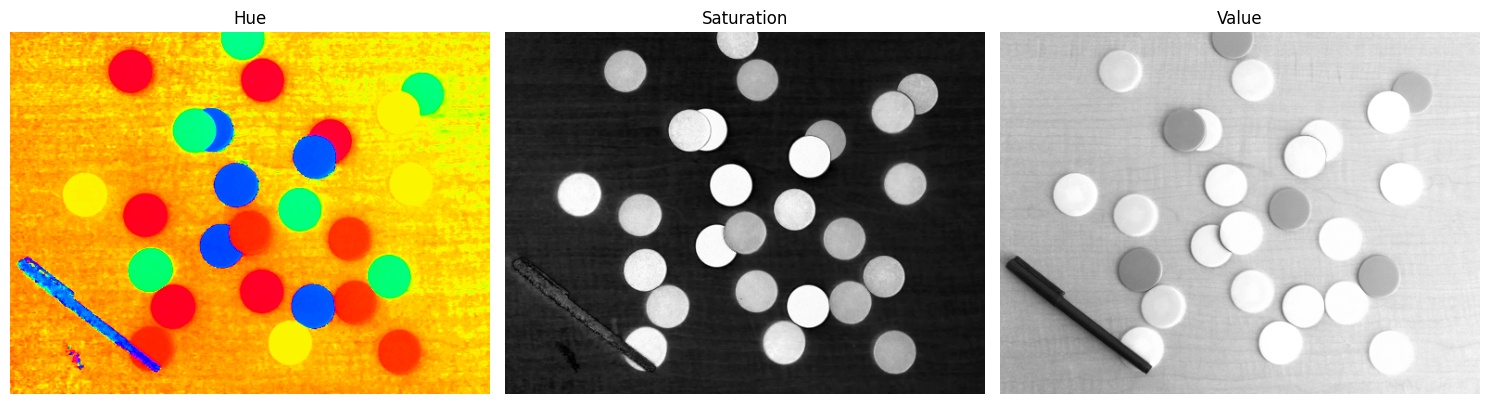

In [16]:
hsv_image = rgb_to_hsv(rgb_image)
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (data, title, cmap, vmin, vmax) in zip(
    axes,
    [
        (hsv_image[..., 0], "Hue", "hsv", 0, 360),
        (hsv_image[..., 1], "Saturation", "gray", 0, 1),
        (hsv_image[..., 2], "Value", "gray", 0, 1),
    ],
    strict=True,
):
    axis.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()

## 5. Máscara de Saturation

Implemente `create_saturation_mask`. A máscara deve ser `S > saturation_threshold`, com threshold no intervalo `[0.0, 1.0]`. Retorne um array `bool` `(H, W)` e não altere HSV.

In [23]:
def create_saturation_mask(hsv, saturation_threshold):
    """Creates a boolean mask for sufficiently saturated pixels."""
    mask = None

    ### START CODE HERE ###

    if saturation_threshold < 0.0 or saturation_threshold > 1.0:
        raise ValueError("Saturation threshold must be between 0.0 and 1.0.")

    mask = hsv[..., 1] > saturation_threshold
    ### END CODE HERE ###

    return mask

## 6. Exploração interativa do limiar

Use o slider para observar quando o background é excluído sem remover os chips. O pipeline de visualização já está pronto.

In [18]:
def update_saturation_mask(saturation_threshold):
    mask = create_saturation_mask(hsv_image, saturation_threshold)
    figure, axes = plt.subplots(1, 3, figsize=(15, 4))
    panels = (
        (rgb_image, "Original", None, None, None),
        (hsv_image[..., 1], "Saturation", "gray", 0, 1),
        (mask, "Chip mask", "gray", 0, 1),
    )
    for axis, (data, title, cmap, vmin, vmax) in zip(axes, panels, strict=True):
        axis.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax)
        axis.set_title(title)
        axis.axis("off")
    figure.tight_layout()


threshold_slider = widgets.FloatSlider(
    value=0.80,
    min=0.0,
    max=1.0,
    step=0.01,
    description="S threshold:",
    continuous_update=True,
)
widgets.interact(update_saturation_mask, saturation_threshold=threshold_slider)

interactive(children=(FloatSlider(value=0.8, description='S threshold:', max=1.0, step=0.01), Output()), _dom_…

<function __main__.update_saturation_mask(saturation_threshold)>

## 7. Histograma de Hue mascarado

Implemente `compute_masked_hue_histogram`. Use apenas `hsv[..., 0][mask]`; pixels de background não podem entrar no histograma. O padrão é 360 bins no intervalo `[0, 360)`. Retorne o histograma e as bordas dos bins.

In [8]:
def compute_masked_hue_histogram(hsv, mask, num_bins=360):
    """Computes the Hue histogram using only masked pixels."""
    histogram = None
    bin_edges = None

    ### START CODE HERE ###

    # TODO
    histogram, bin_edges = np.histogram(hsv[..., 0][mask], bins=num_bins, range=(0, 360))

    ### END CODE HERE ###

    return histogram, bin_edges

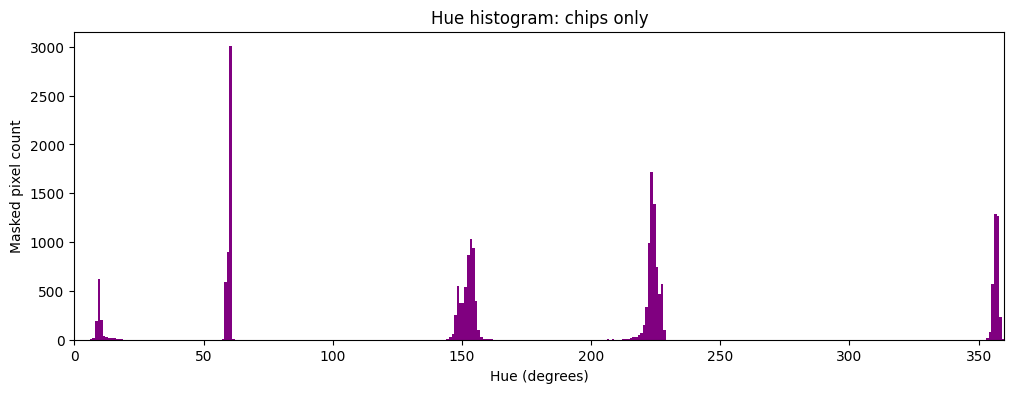

In [9]:
default_threshold = 0.80
chip_mask = create_saturation_mask(hsv_image, default_threshold)
hue_histogram, hue_bin_edges = compute_masked_hue_histogram(hsv_image, chip_mask)
plt.figure(figsize=(12, 4))
plt.bar(
    hue_bin_edges[:-1],
    hue_histogram,
    width=np.diff(hue_bin_edges),
    align="edge",
    color="purple",
)
plt.xlim(0, 360)
plt.xlabel("Hue (degrees)")
plt.ylabel("Masked pixel count")
plt.title("Hue histogram: chips only")
plt.show()

## 8. Faixas de Hue e segmentação

Após observar os picos, as faixas abaixo representam vermelho, laranja, amarelo, verde e azul. Cada item segue `(name, start_degrees, end_degrees)`. A faixa vermelha é circular: começa próxima de 360 graus e termina próxima de 0.

Implemente `segment_hue_ranges`. A saída é uma imagem inteira com `0` para background e `1` a `5` na ordem das faixas. Um intervalo comum deve selecionar start <= H < end.
Um intervalo circular, com start > end, deve selecionar
H >= start ou H < end.

In [10]:
hue_ranges = [
    ("red", 335.0, 5.0),
    ("orange", 5.0, 35.0),
    ("yellow", 45.0, 85.0),
    ("green", 100.0, 180.0),
    ("blue", 190.0, 270.0),
]


def segment_hue_ranges(hsv, chip_mask, hue_ranges):
    """Segments masked pixels into integer labels using Hue intervals."""
    labels = None

    ### START CODE HERE ###

    labels = np.zeros(hsv.shape[:2], dtype=np.uint8)

    h = hsv[..., 0]

    for i, (name, start, end) in enumerate(hue_ranges, start=1):
        if start > end:

            in_range = (h >= start) | (h < end)
        else:

            in_range = (h >= start) & (h < end)

        labels[chip_mask & in_range] = i

    ### END CODE HERE ###

    return labels

## 9. Testes determinísticos

Execute depois de implementar as quatro funções. Os testes verificam RGB para HSV, máscara, histograma somente nos pixels mascarados, cinco classes, circularidade do vermelho, dtype, shape e imutabilidade.

In [24]:
test_rgb = np.array([[[255, 0, 0], [0, 255, 0], [0, 0, 255]]], dtype=np.uint8)
test_rgb_original = test_rgb.copy()
test_hsv = rgb_to_hsv(test_rgb)
assert test_hsv.shape == test_rgb.shape and test_hsv.dtype == np.float64
assert np.isclose(test_hsv[0, 0, 0], 0.0)
assert np.isclose(test_hsv[0, 1, 0], 120.0)
assert np.isclose(test_hsv[0, 2, 0], 240.0)
assert np.allclose(test_hsv[..., 1], 1.0) and np.allclose(test_hsv[..., 2], 1.0)
assert np.array_equal(test_rgb, test_rgb_original)

mask_hsv = np.array(
    [[[0.0, 0.10, 1.0], [30.0, 0.80, 1.0]], [[60.0, 0.40, 1.0], [120.0, 0.90, 1.0]]],
    dtype=np.float64,
)
expected_mask = np.array([[False, True], [False, True]], dtype=bool)
assert np.array_equal(create_saturation_mask(mask_hsv, 0.5), expected_mask)

histogram_hsv = np.zeros((2, 3, 3), dtype=np.float64)
histogram_hsv[..., 0] = np.array([[0, 10, 20], [100, 110, 120]], dtype=np.float64)
histogram_mask = np.array([[True, True, False], [False, False, True]], dtype=bool)
histogram, _ = compute_masked_hue_histogram(histogram_hsv, histogram_mask, num_bins=360)
assert (
    histogram.sum() == 3
    and histogram[0] == 1
    and histogram[10] == 1
    and histogram[120] == 1
)

segment_hsv = np.zeros((1, 6, 3), dtype=np.float64)
segment_hsv[0, :, 0] = [0.0, 30.0, 60.0, 120.0, 240.0, 355.0]
segment_hsv[..., 1:] = 1.0
segment_mask = np.array([[True, True, True, True, True, True]], dtype=bool)
labels = segment_hue_ranges(segment_hsv, segment_mask, hue_ranges)
assert np.array_equal(labels, np.array([[1, 2, 3, 4, 5, 1]]))
background_mask = np.array([[False, True, True, True, True, True]], dtype=bool)
assert segment_hue_ranges(segment_hsv, background_mask, hue_ranges)[0, 0] == 0

try:
    create_saturation_mask(mask_hsv, 1.1)
except ValueError:
    pass
else:
    raise AssertionError("Invalid threshold must be rejected.")
print("Test passed!")

Test passed!


## 10. Resultado final

Aplique as faixas à máscara escolhida e use uma paleta visual distinta para cada label.

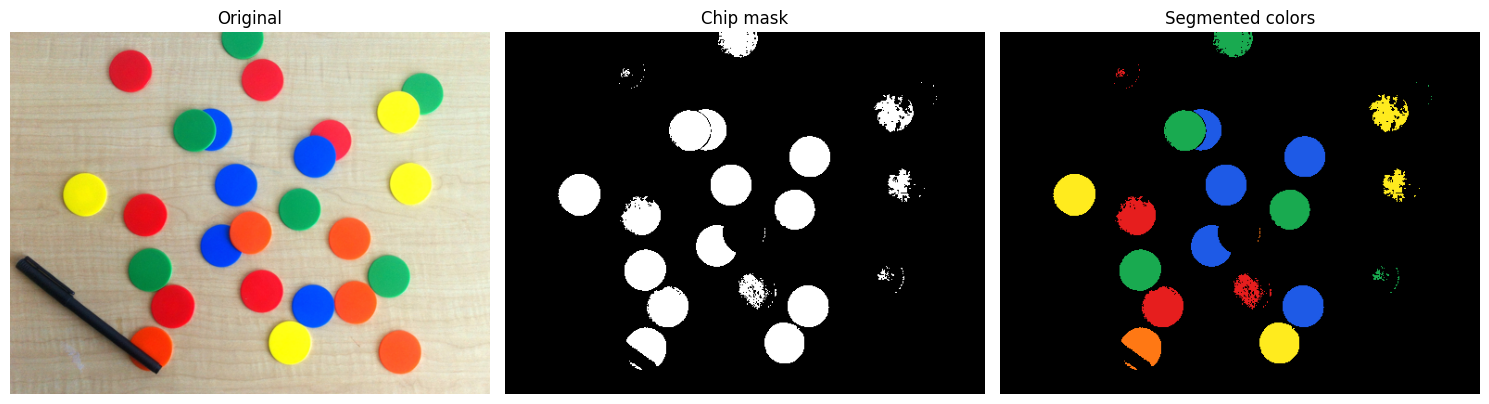

In [13]:
labels = segment_hue_ranges(hsv_image, chip_mask, hue_ranges)
palette = np.array(
    [
        [0, 0, 0],
        [230, 30, 30],
        [255, 120, 20],
        [255, 235, 30],
        [25, 170, 80],
        [30, 90, 230],
    ],
    dtype=np.uint8,
)
segmented_colors = palette[labels]
figure, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, (data, title, cmap) in zip(
    axes,
    [
        (rgb_image, "Original", None),
        (chip_mask, "Chip mask", "gray"),
        (segmented_colors, "Segmented colors", None),
    ],
    strict=True,
):
    axis.imshow(data, cmap=cmap)
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()

## Explore

Responda: por que Saturation separa bem chips e background? O que acontece com thresholds muito baixos ou altos? Por que o histograma de Hue deve excluir o background? Quantos picos principais aparecem? Por que vermelho exige uma faixa circular? Quais limitações existem ao definir manualmente os intervalos de Hue?

Resposta: Como os chips tem um nível de saturação diferente do background, são mais intensos, podemos fazer uma distinção entre esses elementos em função do intervalo.  Usar thresholds nos extremos, baixos ou alto, aceita todos os pixels da imagem, gerando uma imagem branca. O caso contrário, um threshold alto, nenhum píxel é aceito, gerando uma imagem preta. O ideal são valores intermediários para captar apenas as cores mais saturadas. Se considerar o background no histograma, não vamos distinguir bem os elementos desejados de qualquer outros elementos no background. Como o Hue é visto como ângulo, existe a distorção entre o 0º e 360º, pois representam o mesmo ponto e surge esse problema de salto de continuidade. No entanto, a faixa de valores próxima do ponto, ou seja, maior que zero e abaixo de 360, representam o vermelho. O problema de definir manualmente o Hue é separar adequadamente o ponto que separa uma cor de outra.